In [2]:
import pandas as pd
df = pd.read_csv("../data/Global Superstore Retail Dataset.csv")
df.head()


,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07 00:00:00.000,CA-2011-130813,...,19,Consumer,2011-01-09 00:00:00.000,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21 00:00:00.000,CA-2011-148614,...,19,Consumer,2011-01-26 00:00:00.000,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,21,Consumer,2011-08-09 00:00:00.000,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,111,Consumer,2011-08-09 00:00:00.000,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29 00:00:00.000,CA-2011-146969,...,6,Consumer,2011-10-03 00:00:00.000,Standard Class,1.32,California,Paper,2011,North America,40


In [3]:
print(df.shape)

(51290, 27)


In [4]:
print(df.columns)

Index(['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name',
       'Discount', 'Market', '记录数', 'Order.Date', 'Order.ID', 'Order.Priority',
       'Product.ID', 'Product.Name', 'Profit', 'Quantity', 'Region', 'Row.ID',
       'Sales', 'Segment', 'Ship.Date', 'Ship.Mode', 'Shipping.Cost', 'State',
       'Sub.Category', 'Year', 'Market2', 'weeknum'],
      dtype='str')


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  str    
 1   City            51290 non-null  str    
 2   Country         51290 non-null  str    
 3   Customer.ID     51290 non-null  str    
 4   Customer.Name   51290 non-null  str    
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  str    
 7   记录数             51290 non-null  int64  
 8   Order.Date      51290 non-null  str    
 9   Order.ID        51290 non-null  str    
 10  Order.Priority  51290 non-null  str    
 11  Product.ID      51290 non-null  str    
 12  Product.Name    51290 non-null  str    
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  str    
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-null  int64  
 1

In [6]:
missing_values = df.isnull().sum()

print(missing_values)

Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64


In [7]:

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)


Duplicate rows: 0


In [8]:

print(df[["Sales", "Profit", "Quantity", "Discount", "Shipping.Cost"]].describe())


              Sales        Profit      Quantity      Discount  Shipping.Cost
count  51290.000000  51290.000000  51290.000000  51290.000000   51290.000000
mean     246.498440     28.610982      3.476545      0.142908      26.375818
std      487.567175    174.340972      2.278766      0.212280      57.296810
min        0.000000  -6599.978000      1.000000      0.000000       0.002000
25%       31.000000      0.000000      2.000000      0.000000       2.610000
50%       85.000000      9.240000      3.000000      0.000000       7.790000
75%      251.000000     36.810000      5.000000      0.200000      24.450000
max    22638.000000   8399.976000     14.000000      0.850000     933.570000


In [9]:

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)


Duplicate rows: 0


In [10]:


df["Order.Date"] = pd.to_datetime(
    df["Order.Date"], errors="coerce"
)


df["Ship.Date"] = pd.to_datetime(
    df["Ship.Date"], errors="coerce"
)


print(df[["Order.Date", "Ship.Date"]].dtypes)


Order.Date    datetime64[us]
Ship.Date     datetime64[us]
dtype: object


In [11]:

print("Invalid order dates:", df["Order.Date"].isnull().sum())
print("Invalid shipping dates:", df["Ship.Date"].isnull().sum())


Invalid order dates: 0
Invalid shipping dates: 0


In [12]:

print("First order date:", df["Order.Date"].min())
print("Last order date:", df["Order.Date"].max())

print("First shipping date:", df["Ship.Date"].min())
print("Last shipping date:", df["Ship.Date"].max())


First order date: 2011-01-01 00:00:00
Last order date: 2014-12-31 00:00:00
First shipping date: 2011-01-03 00:00:00
Last shipping date: 2015-01-07 00:00:00


In [13]:
df["Shipping.Duration"] = (
    df["Ship.Date"] - df["Order.Date"]
).dt.days
print(
    df[["Order.Date", "Ship.Date", "Shipping.Duration"]].head(10)
)

  Order.Date  Ship.Date  Shipping.Duration
0 2011-01-07 2011-01-09                  2
1 2011-01-21 2011-01-26                  5
2 2011-08-05 2011-08-09                  4
3 2011-08-05 2011-08-09                  4
4 2011-09-29 2011-10-03                  4
5 2011-10-19 2011-10-19                  0
6 2011-11-04 2011-11-11                  7
7 2011-11-12 2011-11-16                  4
8 2011-11-22 2011-11-26                  4
9 2011-12-05 2011-12-10                  5


In [14]:

print(df["Shipping.Duration"].describe())


count    51290.000000
mean         3.969370
std          1.729437
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max          7.000000
Name: Shipping.Duration, dtype: float64


In [15]:

print(
    "Negative shipping durations:",
    (df["Shipping.Duration"] < 0).sum()
)

print(
    "Same-day shipments:",
    (df["Shipping.Duration"] == 0).sum()
)

print(
    "Shipments taking more than 5 days:",
    (df["Shipping.Duration"] > 5).sum()
)


Negative shipping durations: 0
Same-day shipments: 2600
Shipments taking more than 5 days: 9312


In [16]:

print("Invalid order dates:", df["Order.Date"].isnull().sum())
print("Invalid shipping dates:", df["Ship.Date"].isnull().sum())


Invalid order dates: 0
Invalid shipping dates: 0


In [17]:

print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())
print("Total Quantity Sold:", df["Quantity"].sum())
print("Average Order-Line Sales:", df["Sales"].mean())


Total Sales: 12642905
Total Profit: 1467457.2912800002
Total Quantity Sold: 178312
Average Order-Line Sales: 246.49844024176252


In [18]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .reset_index()
)

print(category_sales)

          Category    Sales
0        Furniture  4110884
1  Office Supplies  3787330
2       Technology  4744691


In [19]:
category_performance = (
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)

print(category_performance)

          Category    Sales        Profit
0        Furniture  4110884  285204.72380
1  Office Supplies  3787330  518473.83430
2       Technology  4744691  663778.73318


In [20]:

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

profit_margin = (total_profit / total_sales) * 100

print(f"Overall Profit Margin: {profit_margin:.2f}%")


Overall Profit Margin: 11.61%


In [23]:
category_performance["Profit Margin (%)"] = (
    category_performance["Profit"]
    / category_performance["Sales"]
) * 100

print(category_performance.round(2
                                 ))

          Category    Sales     Profit  Profit Margin (%)
0        Furniture  4110884  285204.72               6.94
1  Office Supplies  3787330  518473.83              13.69
2       Technology  4744691  663778.73              13.99


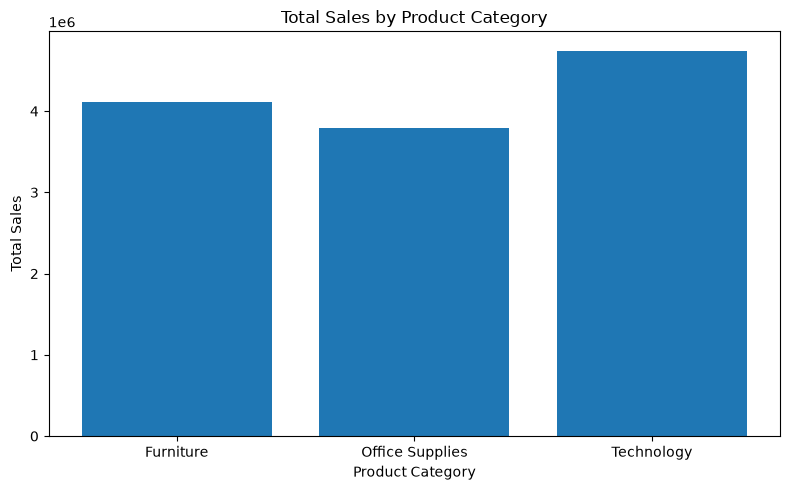

In [24]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    category_sales["Category"],
    category_sales["Sales"]
)

plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.title("Total Sales by Product Category")

plt.tight_layout()
plt.show()


In [25]:
yearly_performance = (
    df.groupby("Year")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)

print(yearly_performance)

   Year    Sales        Profit
0  2011  2259511  248940.81154
1  2012  2677493  307415.27910
2  2013  3405860  406935.23018
3  2014  4300041  504165.97046


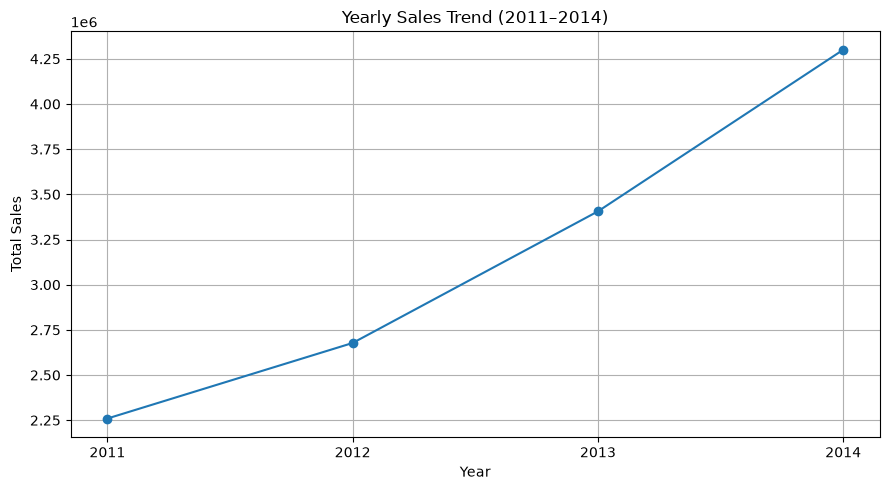

In [26]:

plt.figure(figsize=(9, 5))

plt.plot(
    yearly_performance["Year"],
    yearly_performance["Sales"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.title("Yearly Sales Trend (2011–2014)")

plt.xticks(yearly_performance["Year"])
plt.grid(True)
plt.tight_layout()
plt.show()


In [27]:

country_performance = (
    df.groupby("Country")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)


country_performance = country_performance.sort_values(
    by="Sales",
    ascending=False
)

print(country_performance.head(10))


            Country    Sales        Profit
139   United States  2297354  286397.02170
6         Australia   925257  103907.43300
44           France   858930  109029.00300
26            China   700591  150683.08500
47          Germany   628857  107322.82050
81           Mexico   622620  102818.09752
57            India   589664  129071.83500
138  United Kingdom   528570  111900.15000
58        Indonesia   404887   15608.67790
17           Brazil   361098   30090.49896


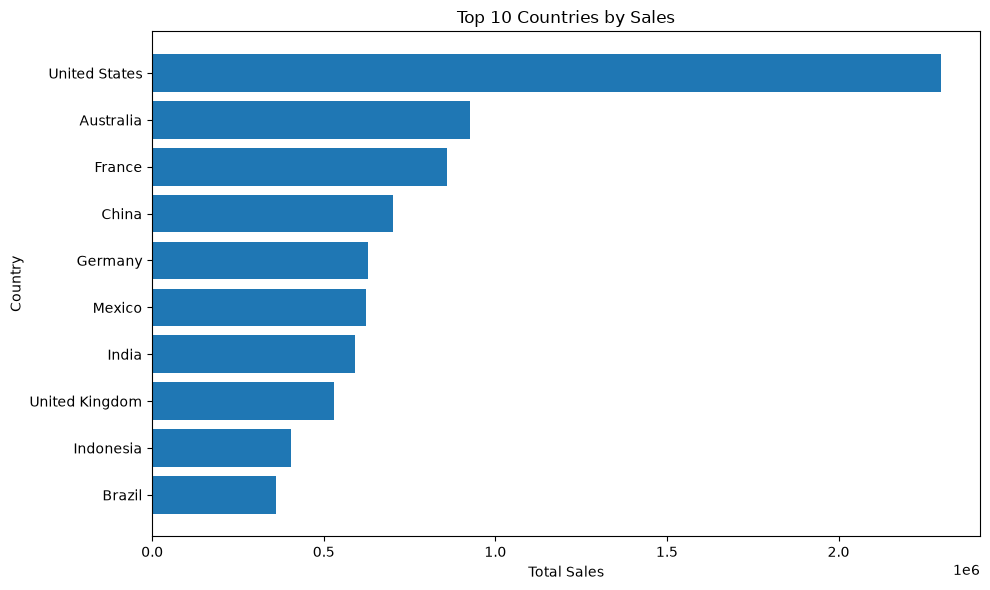

In [ ]:
top_countries = country_performance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries["Country"],
    top_countries["Sales"]
)

plt.xlabel("Total Sales")
plt.ylabel("Country")
plt.title("Top 10 Countries by Sales")

# Put the highest-sales country at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [29]:

print(df["Market"].unique())


<ArrowStringArray>
['US', 'EU', 'LATAM', 'Africa', 'APAC', 'EMEA', 'Canada']
Length: 7, dtype: str


In [30]:

market_performance = (
    df.groupby("Market")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)

market_performance = market_performance.sort_values(
    by="Sales",
    ascending=False
)

print(market_performance)


   Market    Sales        Profit
0    APAC  3585833  436000.04900
4      EU  2938139  372829.74150
6      US  2297354  286397.02170
5   LATAM  2164687  221643.48708
3    EMEA   806184   43897.97100
1  Africa   783776   88871.63100
2  Canada    66932   17817.39000


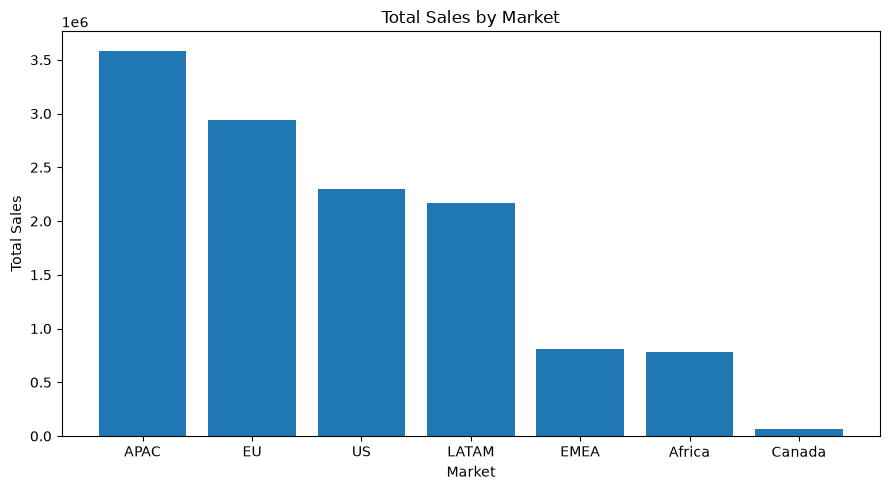

In [31]:
plt.figure(figsize=(9, 5))

plt.bar(
    market_performance["Market"],
    market_performance["Sales"]
)

plt.xlabel("Market")
plt.ylabel("Total Sales")
plt.title("Total Sales by Market")

plt.tight_layout()
plt.show()

In [32]:

product_performance = (
    df.groupby("Product.Name")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)

product_performance = product_performance.sort_values(
    by="Sales",
    ascending=False
)

top_products = product_performance.head(10)

print(top_products)


                                           Product.Name  Sales      Profit
310                        Apple Smart Phone, Full Size  86936   5921.5786
970                        Cisco Smart Phone, Full Size  76441  17238.5206
2415                    Motorola Smart Phone, Full Size  73159  17027.1130
2501                       Nokia Smart Phone, Full Size  71904   9938.1955
866               Canon imageCLASS 2200 Advanced Copier  61600  25199.9280
1837         Hon Executive Leather Armchair, Adjustable  58200   5997.2541
2631  Office Star Executive Leather Armchair, Adjust...  50667   4710.9840
1714  Harbour Creations Executive Leather Armchair, ...  50120  10427.3260
2988                      Samsung Smart Phone, Cordless  48654   -198.0900
2502                  Nokia Smart Phone, with Caller ID  47880   9465.3257


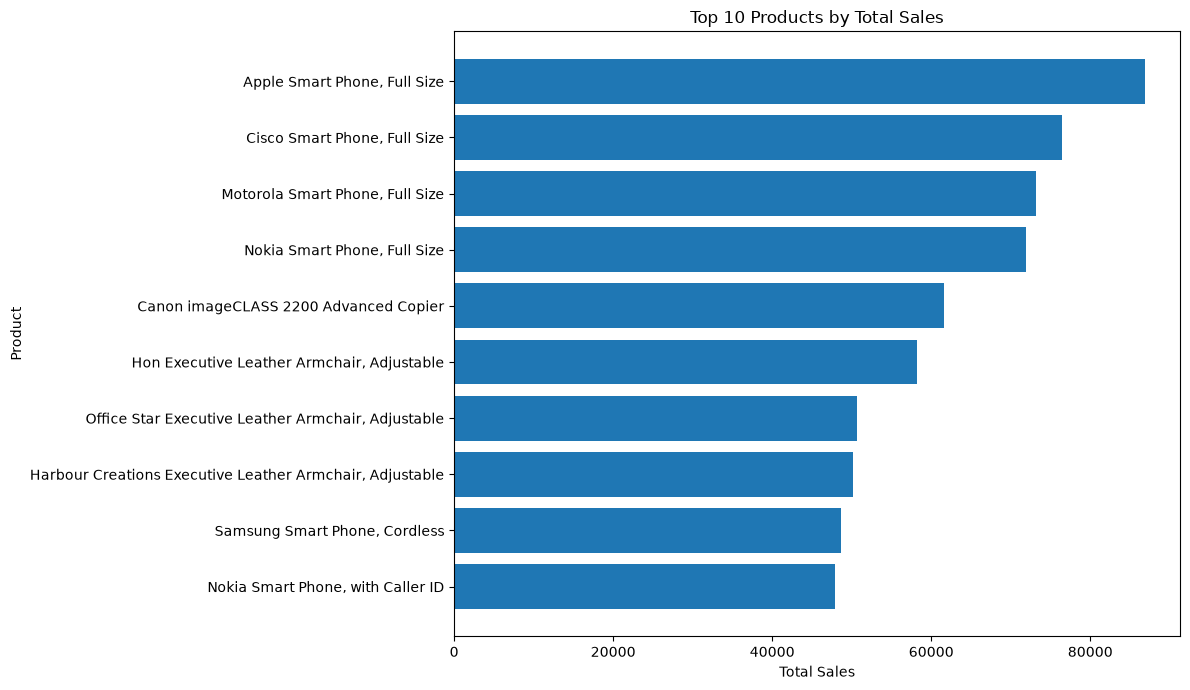

In [33]:
plt.figure(figsize=(12, 7))

plt.barh(
    top_products["Product.Name"],
    top_products["Sales"]
)

plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.title("Top 10 Products by Total Sales")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [34]:

subcategory_performance = (
    df.groupby("Sub.Category")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)

# Rank by profit, from highest to lowest
subcategory_performance = subcategory_performance.sort_values(
    by="Profit",
    ascending=False
)

print(subcategory_performance)


   Sub.Category    Sales        Profit
6       Copiers  1509439  258567.54818
13       Phones  1706874  216717.00580
4     Bookcases  1466559  161924.41950
1    Appliances  1011081  141680.58940
5        Chairs  1501682  140396.26750
0   Accessories   749307  129626.30620
14      Storage  1127124  108461.48980
3       Binders   461952   72449.84600
12        Paper   244307   59207.68270
11     Machines   779071   58867.87300
2           Art   372163   57953.91090
9   Furnishings   385609   46967.42550
7     Envelopes   170926   29601.11630
15     Supplies   243090   22583.26310
10       Labels    73433   15010.51200
8     Fasteners    83254   11525.42410
16       Tables   757034  -64083.38870


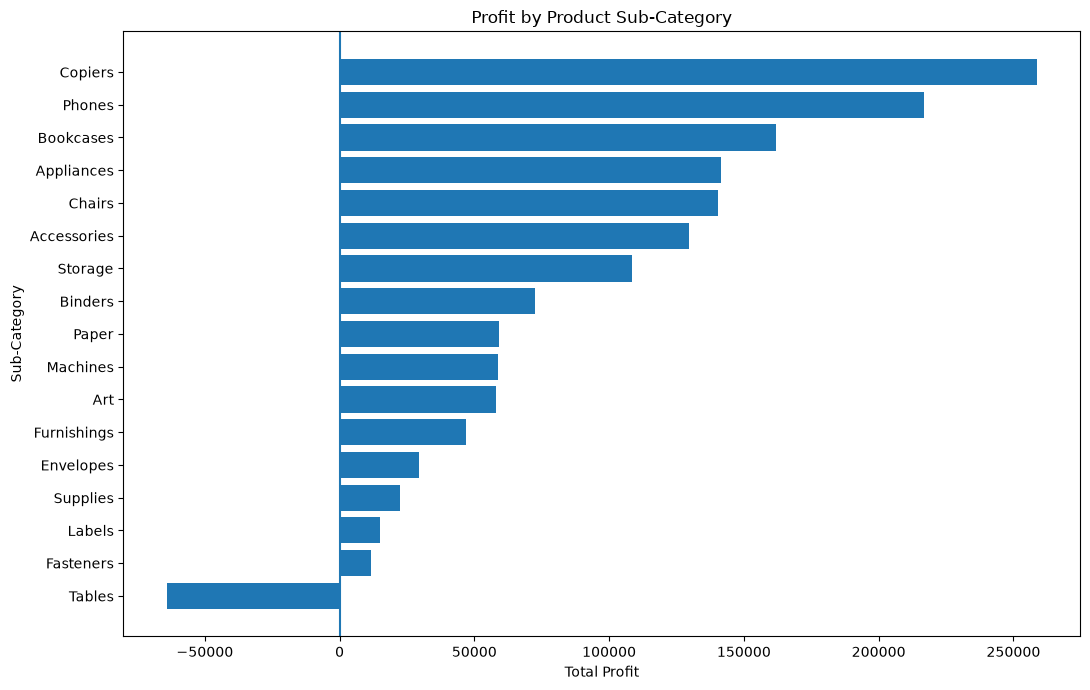

In [35]:
plt.figure(figsize=(11, 7))

plt.barh(
    subcategory_performance["Sub.Category"],
    subcategory_performance["Profit"]
)

plt.axvline(x=0)
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.title("Profit by Product Sub-Category")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [36]:

shipping_performance = (
    df.groupby("Ship.Mode")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Shipping_Days=("Shipping.Duration", "mean"),
        Total_Orders=("Order.ID", "nunique")
    )
    .reset_index()
)

print(shipping_performance.round(2))


        Ship.Mode  Total_Sales  Total_Profit  Average_Shipping_Days  \
0     First Class      1831067     208104.68                   2.18   
1        Same Day       667202      76173.07                   0.04   
2    Second Class      2565747     292583.53                   3.23   
3  Standard Class      7578889     890596.02                   5.00   

   Total_Orders  
0          3821  
1          1347  
2          5119  
3         15154  


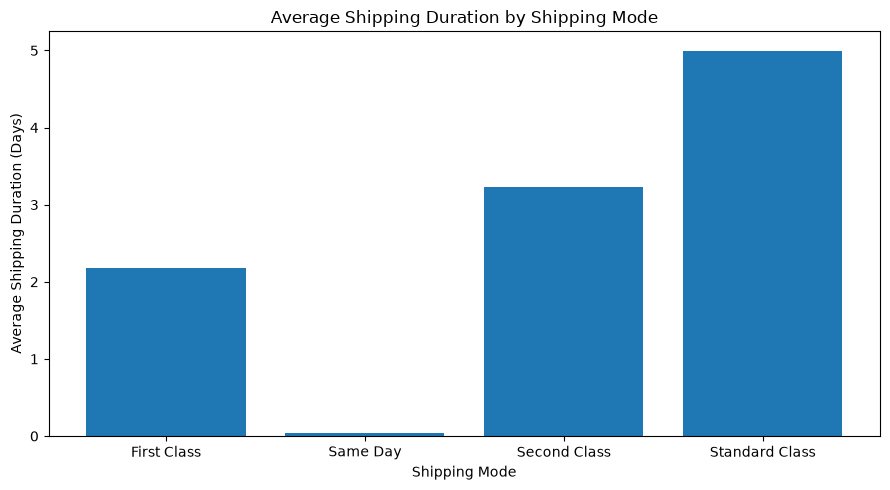

In [37]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_performance["Ship.Mode"],
    shipping_performance["Average_Shipping_Days"]
)

plt.xlabel("Shipping Mode")
plt.ylabel("Average Shipping Duration (Days)")
plt.title("Average Shipping Duration by Shipping Mode")

plt.tight_layout()
plt.show()

In [38]:
import os

os.makedirs("../visuals", exist_ok=True)

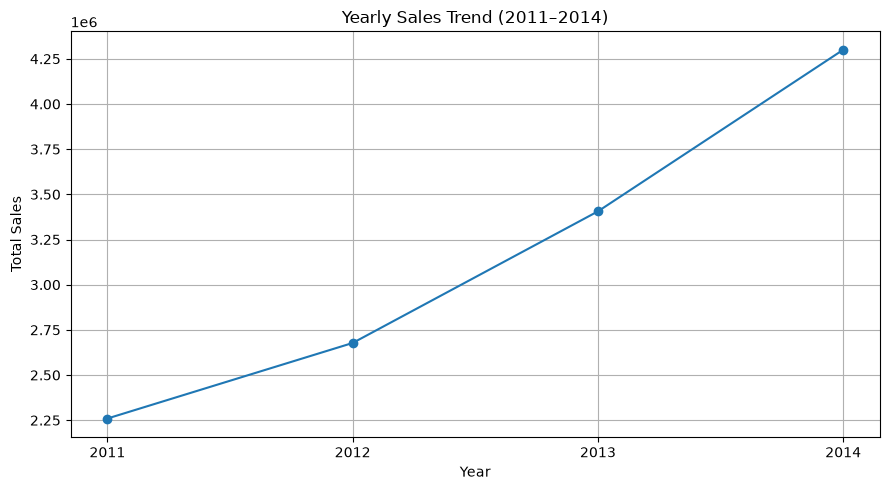

In [39]:
plt.figure(figsize=(9, 5))
plt.plot(
    yearly_performance["Year"],
    yearly_performance["Sales"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.title("Yearly Sales Trend (2011–2014)")
plt.xticks(yearly_performance["Year"])
plt.grid(True)
plt.tight_layout()

plt.savefig("../visuals/yearly_sales_trend.png", dpi=300, bbox_inches="tight")
plt.show()


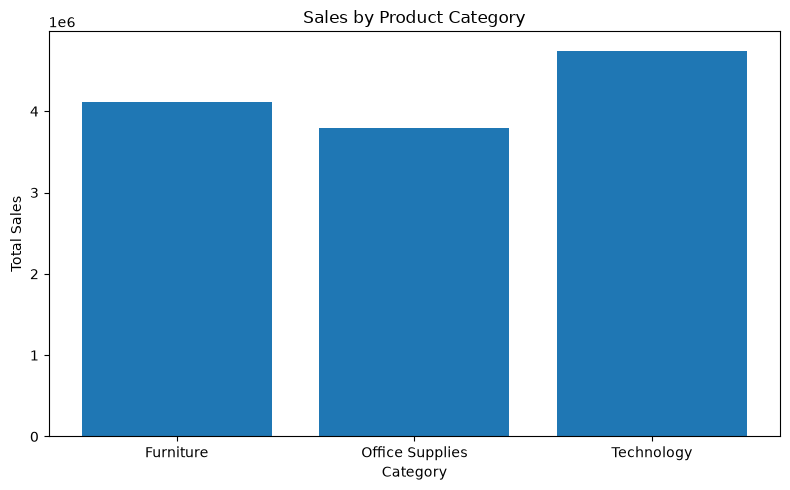

In [40]:

plt.figure(figsize=(8, 5))

plt.bar(
    category_sales["Category"],
    category_sales["Sales"]
)

plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.title("Sales by Product Category")
plt.tight_layout()

plt.savefig("../visuals/category_sales.png", dpi=300, bbox_inches="tight")
plt.show()


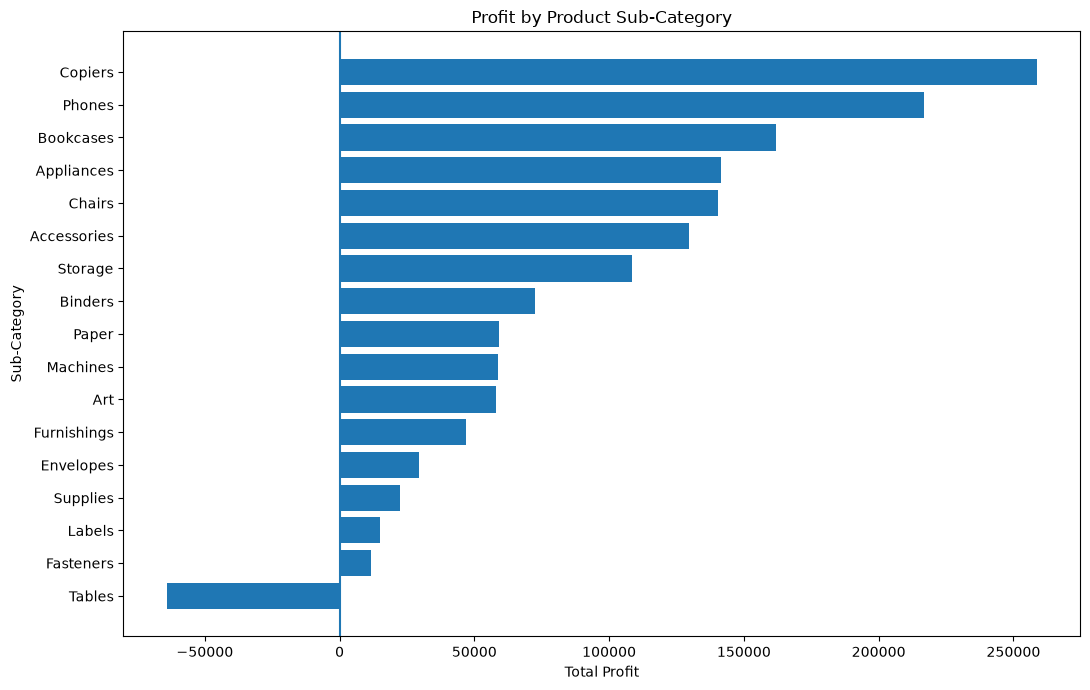

In [41]:

plt.figure(figsize=(11, 7))

plt.barh(
    subcategory_performance["Sub.Category"],
    subcategory_performance["Profit"]
)

plt.axvline(x=0)
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.title("Profit by Product Sub-Category")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("../visuals/subcategory_profit.png", dpi=300, bbox_inches="tight")
plt.show()
